## Image Processing and Computer Vision - Assignment Module \#2

Dorina Dema

Luca De Rosa

Konstantin Kanchev

# Assignment Module 2: Aircraft Classification

The goal of this assignment is to implement a neural network that classifies images of 100 aircraft model variants from the [Fine-Grained Visual Classification of Aircraft (**FGVC-Aircraft**) dataset](https://www.robots.ox.ac.uk/~vgg/data/fgvc-aircraft/). The assignment is divided into two parts: first, you will be asked to implement your own neural network for image classification from scratch; then, you will fine-tune a pretrained network provided by PyTorch.

![](https://raw.githubusercontent.com/CVLAB-Unibo/ipcv-assignment-2/master/fgvc_aircraft_variants.svg)

## Dataset

Download and acces the dataset through its official [PyTorch `FGVCAircraft` class](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.FGVCAircraft.html) (by setting its constructor argument `annotation_level` to `'variant'`).

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


Since images in the dataset have different sizes we use a transform in order to make all images the same size. The size of 256x256 ensures quick training. As part of our training recipe, we also use data augmentation for training data as seen below.

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
])

val_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

train_transform_no_augmentation = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])
test = datasets.FGVCAircraft("./data", split="test", annotation_level="variant",
                            transform=val_transform, download=True)
train = datasets.FGVCAircraft("./data", split="train", annotation_level="variant",
                              transform=train_transform, download=True)
val = datasets.FGVCAircraft("./data", split="val", annotation_level="variant",
                            transform=val_transform, download=True)
tr = DataLoader(train, batch_size=64, shuffle=True)
va = DataLoader(val, batch_size=64)
test_loader = DataLoader(test, batch_size=64, shuffle=False)

train_no_augmentation = datasets.FGVCAircraft("./data", split="train", annotation_level="variant",
                              transform=train_transform, download=True)
tr_no_augmentation = DataLoader(train_no_augmentation, batch_size=64, shuffle=True)

100%|██████████| 2.75G/2.75G [01:23<00:00, 33.1MB/s]


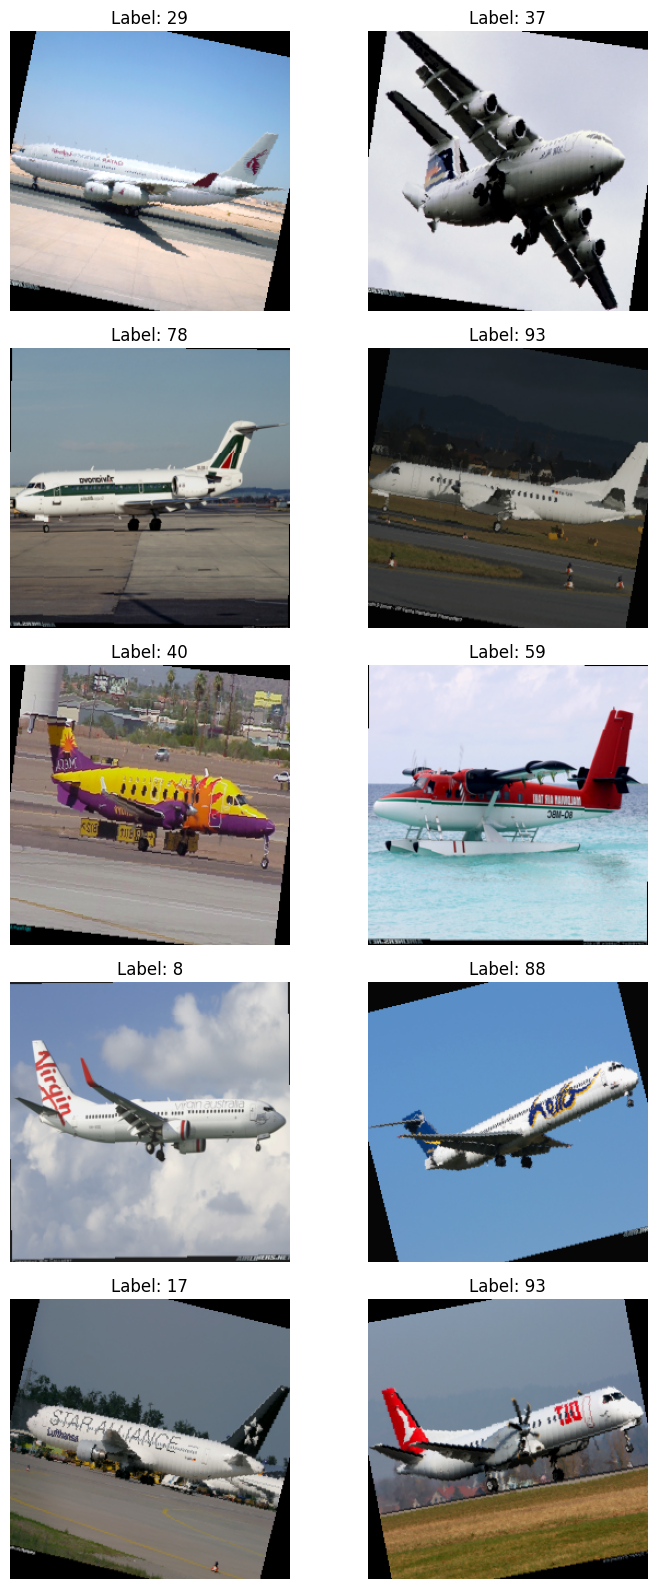

In [ ]:
x, y = next(iter(tr))

fig, axes = plt.subplots(5, 2, figsize=(8, 16))

for i, ax in enumerate(axes.flat):
    img = x[i].permute(1, 2, 0)  # C,H,W -> H,W,C
    ax.imshow(img)
    ax.set_title(f"Label: {y[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `FGVCAircraft`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~50%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~50% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

# Model Definition
Our model is a convolutional neural network with residual blocks. We use a standard sequence of 2D-convolution, activation and max-pooling for our convolutional blocks, each of which is followed by a residual block. Finally a simple classifier with two FC layers uses the extracted features to predict the class of images.

The use of Residual Layers is crucial in ensuring that the preformance of our model scales with its depth. As explained in the lecture increasing the depth of a network in practice does not always directly yield better generalization and can even worsen results. In theory we can always add identity layers to a network and have a deeper network thaer performs the same, but in practice deeper layers cannot recover the identity and thus can harm preformance. Residual Layers resolve this issue by adding skip connections that on an intuitive level can help us skip these useless layers.

The network is relatively large and thus prone to overfitting, which is why most initial design choices were with the aim of regularizing the model. To this end, we add different kinds of regularization techniques until the goal of 50% accuracy is reached and then conduct an ablation study in order to determine the influence on the perforamance of our model.


In the following we provide a definition of our model which yields itsself to ablation easily as well as some utility function for instantiating, training and visualizing the results of our experiments.

In [ ]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3, padding=1
        )
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3, padding=1
        )

        # If dimensions change, project the skip connection
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, 1)
        )

    def forward(self, x):
        identity = self.skip(x)

        x = self.relu(self.conv1(x))
        x = self.conv2(x)

        x = x + identity
        x = self.relu(x)

        return x

#Same as the residual block with no skip connection
class ConvBlock(nn.Module):
  def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, 3, padding=1
        )
        self.relu = nn.ReLU()
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, 3, padding=1
        )


  def forward(self, x):
      x = self.relu(self.conv1(x))
      x = self.conv2(x)
      x = self.relu(x)

      return x
class AircraftCNN(nn.Module):
    def __init__(self, use_batchnorm, use_residual):
        super().__init__()
        self.use_batchnorm = use_batchnorm

        if use_residual:
          self.block = ResidualBlock
        else:
          self.block = ConvBlock
        self.features = nn.Sequential(
            # 256 x 256 -> 128 x 128
            nn.Conv2d(3, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 128 x 128
            self.block(32, 32),

            # 128 x 128 -> 64 x 64
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 64 x 64
            self.block(64, 64),

            # 64 x 64 -> 32 x 32
            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 32 x 32
            self.block(128, 128),
            # 32 x 32 -> 16 x 16
            nn.Conv2d(128, 256, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # 16 x 16
            self.block(256, 256),
        )

        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(256*16*16, 512)
        self.batchnorm = nn.BatchNorm1d(512)
        self.relu = nn.ReLU()
        self.linear2 = nn.Linear(512, 100)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.linear1(x)
        if self.use_batchnorm:
          x = self.batchnorm(x)
        x = self.relu(x)

        x = self.linear2(x)
        return x

In [ ]:
from tqdm.auto import tqdm
def train_loop(model, opt, loss_fn, device, experiment_name="", epochs=30, tr=tr):
  train_loss_per_epoch = []
  train_acc_per_epoch = []
  val_loss_per_epoch = []
  val_acc_per_epoch = []
  for epoch in range(epochs):
      model.train()
      train_correct = train_total = 0
      train_correct_accumulator = train_loss_accumulator = 0
      best_val_acc = 0
      bar = tqdm(tr, desc=f"Epoch {epoch+1}/{epochs}")
      for x, y in bar:
          x, y = x.to(device), y.to(device)

          opt.zero_grad()

          logits = model(x)
          loss = loss_fn(logits, y)

          loss.backward()
          opt.step()

          train_correct += (logits.argmax(1) == y).sum().item()
          train_total += len(y)
          train_acc = train_correct / train_total

          bar.set_postfix(
              loss=f"{loss.item():.4f}",
              acc=f"{train_acc:.3f}"
          )


          train_loss_accumulator += loss.item()
      train_acc_per_epoch.append(train_acc)
      train_loss_per_epoch.append(train_loss_accumulator / len(tr))
      model.eval()
      val_loss = 0.0
      correct = total = 0

      with torch.no_grad():
          for x, y in va:
              x, y = x.to(device), y.to(device)

              logits = model(x)
              val_loss += loss_fn(logits, y).item()

              pred = logits.argmax(1)
              correct += (pred == y).sum().item()
              total += len(y)

      val_loss /= len(va)
      val_acc = correct / total
      val_loss_per_epoch.append(val_loss)
      val_acc_per_epoch.append(val_acc)

      if val_acc > best_val_acc:
        best_val_loss = val_loss
        torch.save(
            model.state_dict(),
            f"/content/drive/MyDrive/AssignmentsIPCV/assignment2/{experiment_name}_aircraft_cnn_best.pth"
        )

      print(f"{experiment_name}:"
          f"Validation — loss: {val_loss:.4f}, "
          f"accuracy: {val_acc:.3f}, "
          f"lr={opt.param_groups[0]['lr']:.2e}"
      )
  return train_loss_per_epoch, train_acc_per_epoch, val_loss_per_epoch, val_acc_per_epoch

In [ ]:
# Utility function for our ablation study that instantiates a model, loss and optimizer object
#and then trains the model providing useful data and plots
def create_model_and_train(use_residual, use_batchnorm, use_label_smoothing, experiment_name, num_epochs, data_loader=tr, learning_rate=2e-4):
  print(f"######### Training: {experiment_name} #########")
  device = "cuda" if torch.cuda.is_available() else "cpu"

  model = AircraftCNN(use_residual=use_residual, use_batchnorm=use_batchnorm).to(device)

  opt = torch.optim.Adam(
      model.parameters(),
      lr=learning_rate
  )
  if use_label_smoothing:
    loss_fn = nn.CrossEntropyLoss(label_smoothing=0.05)
  else:
    loss_fn = nn.CrossEntropyLoss()
  train_loss_per_epoch, train_acc_per_epoch, val_loss_per_epoch, val_acc_per_epoch = train_loop(model, opt, loss_fn, device, experiment_name=experiment_name, epochs=num_epochs, tr=data_loader)

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Loss")
  plt.plot(np.arange(num_epochs), np.array(train_loss_per_epoch), label="Training loss")
  plt.plot(np.arange(num_epochs), np.array(val_loss_per_epoch), label="Validation loss")
  plt.ylim(0, 10)
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Accuracy")
  plt.plot(np.arange(num_epochs), np.array(train_acc_per_epoch), label="Training accuracy")
  plt.plot(np.arange(num_epochs), np.array(val_acc_per_epoch), label="Validation accuracy")
  plt.ylim(0, 1)
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.grid(True)
  plt.show()

  model.eval()
  correct = total = 0
  test_loss = 0.0

  with torch.no_grad():
      for x, y in tqdm(test_loader, desc="Testing"):
          x, y = x.to(device), y.to(device)

          logits = model(x)
          loss = loss_fn(logits, y)

          test_loss += loss.item() * y.size(0)
          correct += (logits.argmax(1) == y).sum().item()
          total += y.size(0)

  test_loss /= total
  test_acc = correct / total

  print(f"{experiment_name}: Test — loss: {test_loss:.4f}, accuracy: {test_acc:.3f}")

## Training and Ablation Study

In the following we show the training and results of the model we used to reach more than 50% testing accuracy. Furthermore, we conduct an ablation study on the main design choices in order to evaluate which of them have a significant contribution to our recipe.

######### Training: OUR_MODEL #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL:Validation — loss: 5.0457, accuracy: 0.013, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL:Validation — loss: 4.6518, accuracy: 0.047, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL:Validation — loss: 2.3096, accuracy: 0.525, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL:Validation — loss: 2.3182, accuracy: 0.516, lr=2.00e-04


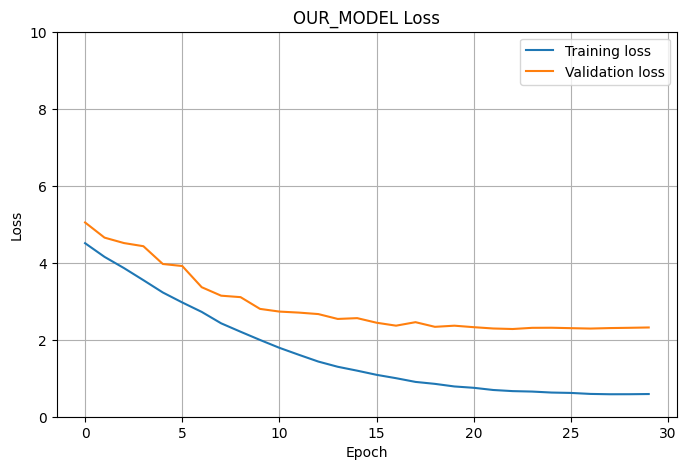

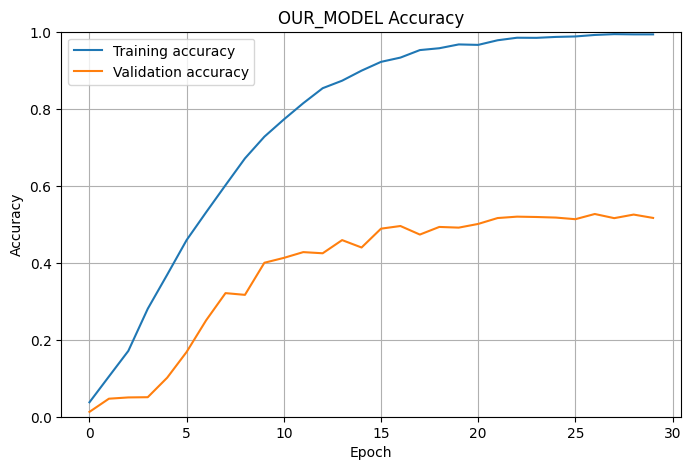

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL: Test — loss: 2.3445, accuracy: 0.507


In [ ]:
create_model_and_train(use_residual=True,
                       use_batchnorm=True, use_label_smoothing=True,
                       experiment_name="OUR_MODEL", num_epochs=30)


######### Training: MODEL_NO_RESIDUAL #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_RESIDUAL:Validation — loss: 5.9526, accuracy: 0.010, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_RESIDUAL:Validation — loss: 37.6785, accuracy: 0.010, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_RESIDUAL:Validation — loss: 2.7050, accuracy: 0.413, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_RESIDUAL:Validation — loss: 2.6417, accuracy: 0.422, lr=2.00e-04


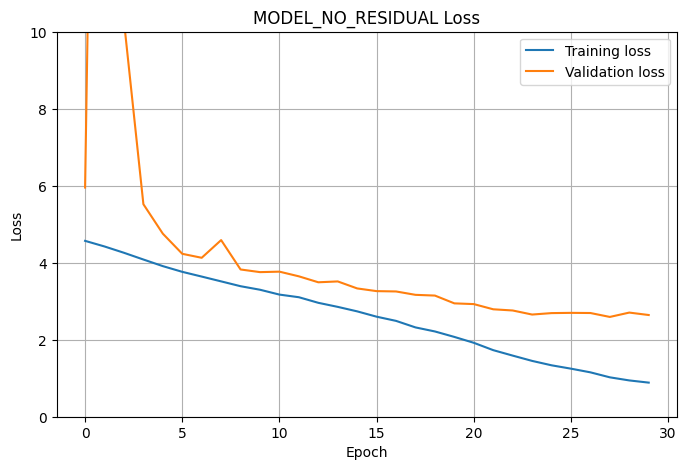

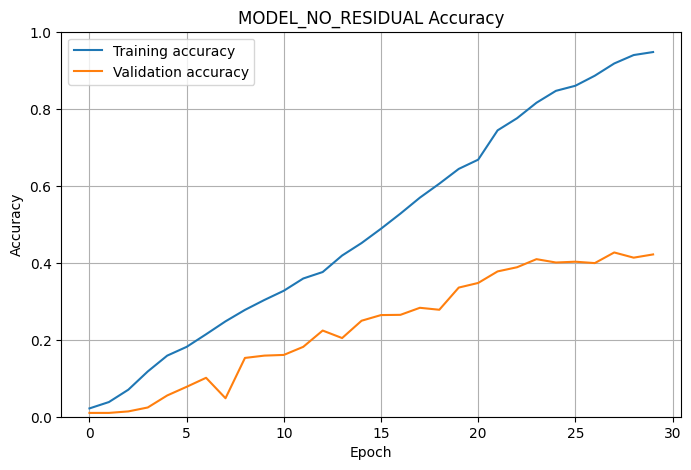

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_RESIDUAL: Test — loss: 2.6671, accuracy: 0.412


In [ ]:
#Ablation: Removing Residual Blocks
create_model_and_train(use_residual=False,
                       use_batchnorm=True, use_label_smoothing=True,
                       experiment_name="MODEL_NO_RESIDUAL", num_epochs=30)

######### Training: MODEL_NO_BATCHNORM #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM:Validation — loss: 4.5822, accuracy: 0.015, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM:Validation — loss: 4.5199, accuracy: 0.019, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM:Validation — loss: 4.2069, accuracy: 0.236, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM:Validation — loss: 4.2680, accuracy: 0.239, lr=2.00e-04


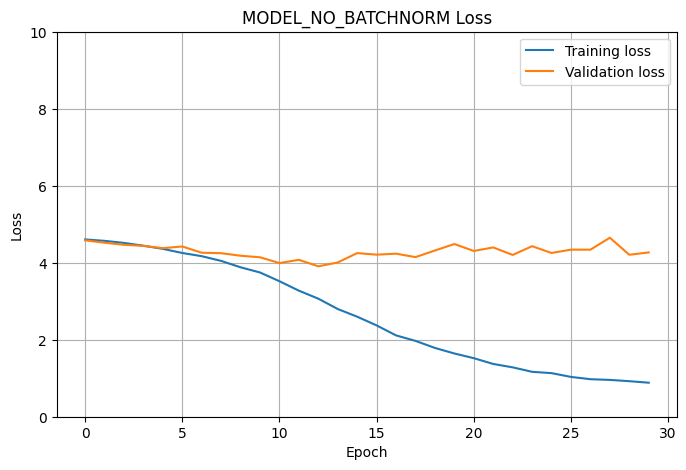

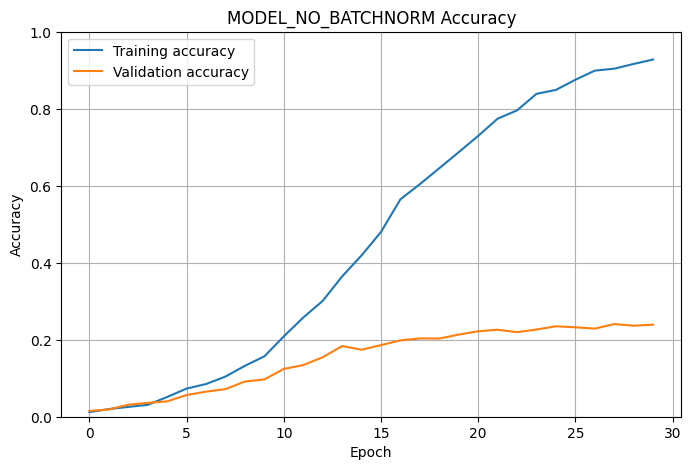

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM: Test — loss: 4.2465, accuracy: 0.238


In [ ]:
# Ablation: Removing Batch Norm
create_model_and_train(use_residual=True,
                       use_batchnorm=False, use_label_smoothing=True,
                       experiment_name="MODEL_NO_BATCHNORM", num_epochs=30)

######### Training: MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE #########


Epoch 1/50:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE:Validation — loss: 4.6035, accuracy: 0.015, lr=5.00e-05


Epoch 2/50:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE:Validation — loss: 4.5553, accuracy: 0.013, lr=5.00e-05


Epoch 3/50:   0%|          | 0/53 [00:00<?, ?it/s]

... (91 outputs left out)

Epoch 49/50:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE:Validation — loss: 4.4607, accuracy: 0.218, lr=5.00e-05


Epoch 50/50:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE:Validation — loss: 4.3003, accuracy: 0.221, lr=5.00e-05


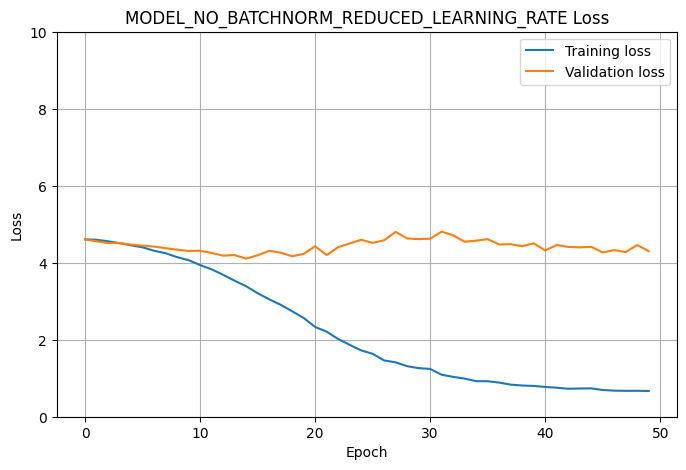

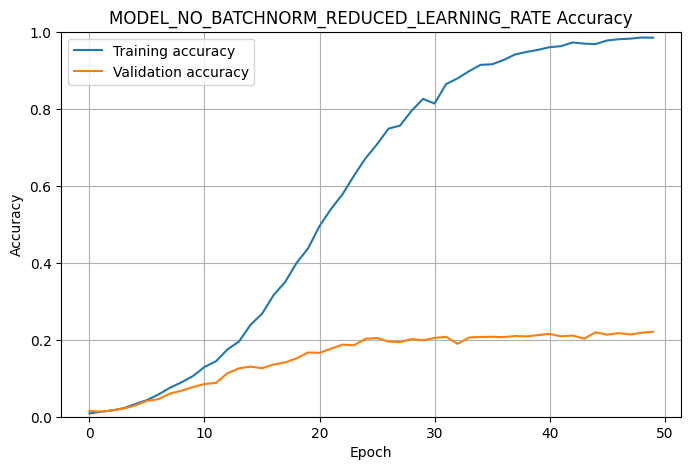

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE: Test — loss: 4.3713, accuracy: 0.215


In [ ]:
# Ablation: Removing Batch Norm and Adjusting Learning Rate
create_model_and_train(use_residual=True,
                       use_batchnorm=False, use_label_smoothing=True,
                       experiment_name="MODEL_NO_BATCHNORM_REDUCED_LEARNING_RATE", num_epochs=50, learning_rate=5e-5)

######### Training: MODEL_NO_LABEL_SMOOTHING #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_LABEL_SMOOTHING:Validation — loss: 5.4230, accuracy: 0.012, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_LABEL_SMOOTHING:Validation — loss: 4.5794, accuracy: 0.024, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_LABEL_SMOOTHING:Validation — loss: 1.8760, accuracy: 0.544, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_LABEL_SMOOTHING:Validation — loss: 1.8640, accuracy: 0.539, lr=2.00e-04


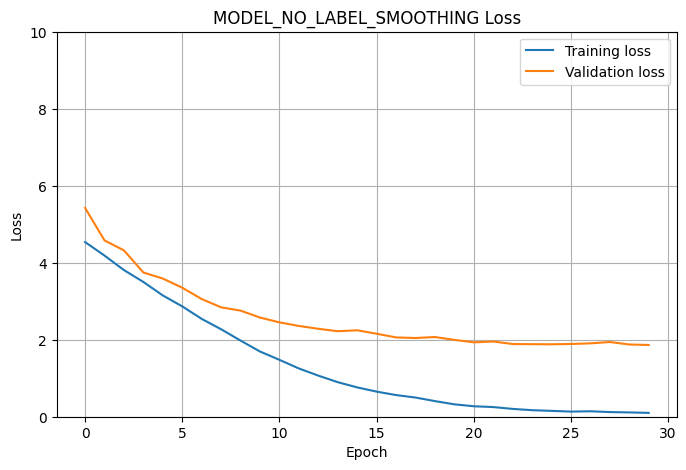

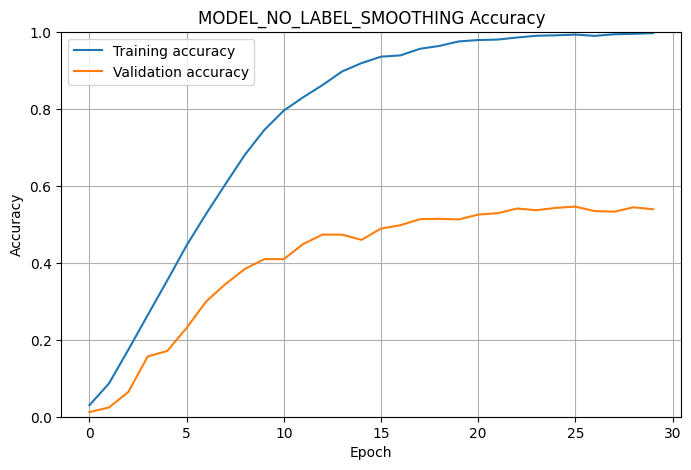

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_LABEL_SMOOTHING: Test — loss: 1.8849, accuracy: 0.532


In [ ]:
# Ablation: Removing Label Smoothing
create_model_and_train(use_residual=True,
                       use_batchnorm=True, use_label_smoothing=False,
                       experiment_name="MODEL_NO_LABEL_SMOOTHING", num_epochs=30)

######### Training: MODEL_NO_DATA_AUGMENTATION #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_DATA_AUGMENTATION:Validation — loss: 4.8385, accuracy: 0.017, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_DATA_AUGMENTATION:Validation — loss: 5.1517, accuracy: 0.029, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_DATA_AUGMENTATION:Validation — loss: 2.2201, accuracy: 0.546, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_DATA_AUGMENTATION:Validation — loss: 2.2131, accuracy: 0.544, lr=2.00e-04


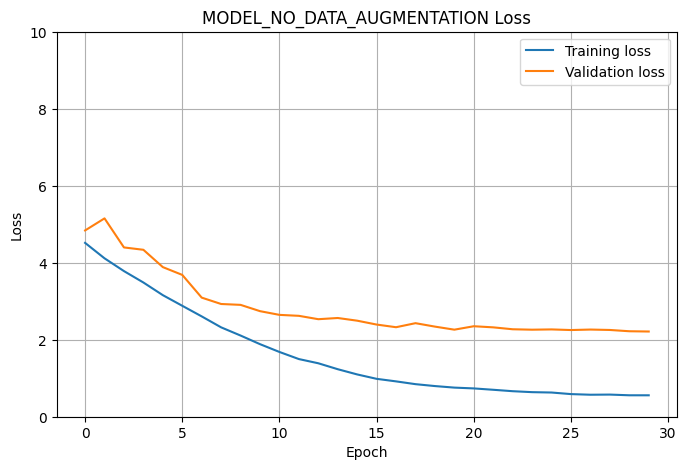

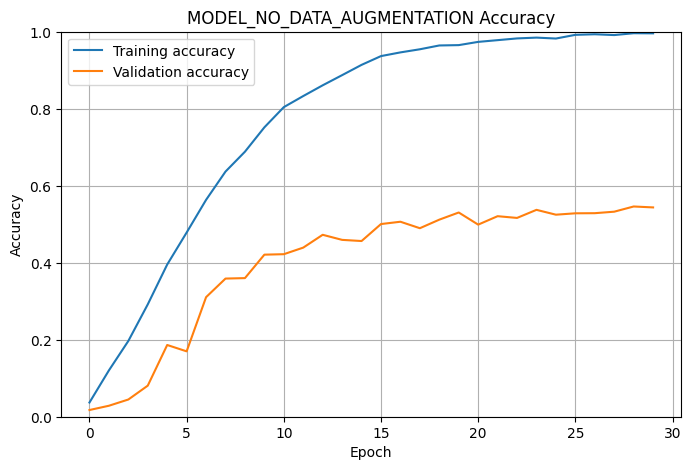

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

MODEL_NO_DATA_AUGMENTATION: Test — loss: 2.2178, accuracy: 0.545


In [ ]:
# Ablation: Removing Data Augmentation
create_model_and_train(use_residual=True,
                       use_batchnorm=True, use_label_smoothing=True,
                       experiment_name="MODEL_NO_DATA_AUGMENTATION", num_epochs=30, data_loader=tr_no_augmentation)

## Main Takaways from the Ablation Study w.r.t Accuracy

Our ablation study demonstrates the importance of the Residual Layers and Batch Normalization in our network. Without said design choices we observe a drop in accuracy of 0.095 and 0.269 respectively, which is significant considering that the number of possible labels is 100. On the other hand, ablating the label smoothing increases accuracy by 0.025. Meaning that adding label smoothing likely did not improve our model. In a similar fashion, removing data augmentation seems to only slightly increase accuracy.

## A Closer Look at Training Behaviour and Loss

Looking at the loss per epoch, it is evident that removing **Residual Layers** results in instability at the beginning of training. That said, after the first 5 epochs training seems to stabilize, after which the validation loss follows the training loss similarly to our model.

When removing the **Batch Norm** we observe a more interesting behavior. While validation accuracy increases and is in any case better than random guessing (which would give an accuracy of 0.01) the validation loss varies between epochs but ultimately does not decrease significantly (4.5822 after epoch 1 vs 4.2680 after epoch 30). This could imply that while the model is able to predict the correct class in a significant number of cases (23.8% accuracy in testing), the distributions outputted are not confident and thus result in a hight cross-entropy.

In a further experiment we evaluate **removing the Batch Norm layer but also reducing the learning rate**. The reasoning behind this is that Batch Norm smooths the loss landscape and thus in general allows higher learning rates to be used. We wanted to test whether the unsuccesfull convergence in the previous experiment was due to the learning rate being too high after removing this smoothing. That said, after reducing the learning rate by a factor of 4 and training for 20 extra epochs we observe basically the same behaviour. We believe that it is possible that reducing the learning rate even more could improve convergence, but even so the added cost of longer training justifies the use of Batch Norm in our network.

Both our original proposal and the variant without **Label Smoothing** exhibit a similar behaviour during training and similar accuracy results. When examining the values of the loss function between the two variants, we notice an inherent property of Label Smoothing, namely that it yields a slightly higher cross-entropy loss due to the soft distribution that it expects.

Finally, **Data Augmentation** seems to be not as significant for our model as we originally expected (it was one of the first decisions we made). The training behaviour of the ablated model closely resembles that of the original one and achieves a similar test loss.

## Comment on Other Hyperparameters

Other hyperparameters that can be evaluated are the learning rate, number of epochs, batch size and resizing of the images. Even though we do not explicitly do an ablation study on them, we believe that the values we have chosen are suitable and our results are still informative (e.g. in the early stages of our project we did try using different sizes of images, learning rates and number of epochs and we kept using the values that seemed to empirically work "well enough").

## Improved Model

As shown in our ablation study, there are features that did not provide significant improvement in test accuracy. In order to keep our model simple, we are going to train it again, mantaining only the design decisions that showed a significant improvement.

######### Training: OUR_MODEL_IMPROVED #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL_IMPROVED:Validation — loss: 4.6976, accuracy: 0.021, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL_IMPROVED:Validation — loss: 4.3921, accuracy: 0.055, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL_IMPROVED:Validation — loss: 1.8163, accuracy: 0.573, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL_IMPROVED:Validation — loss: 1.8035, accuracy: 0.575, lr=2.00e-04


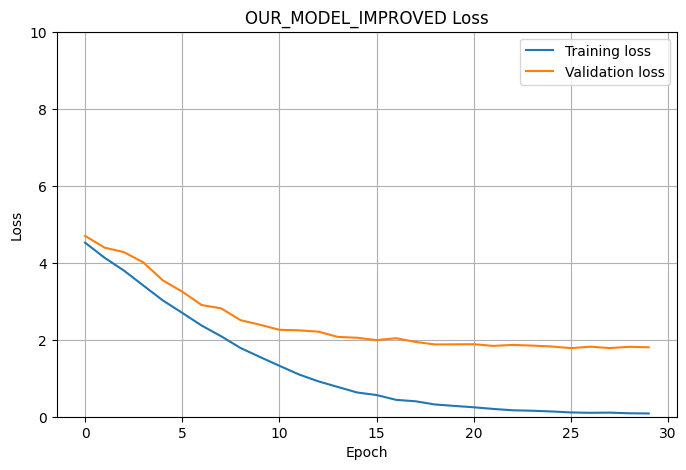

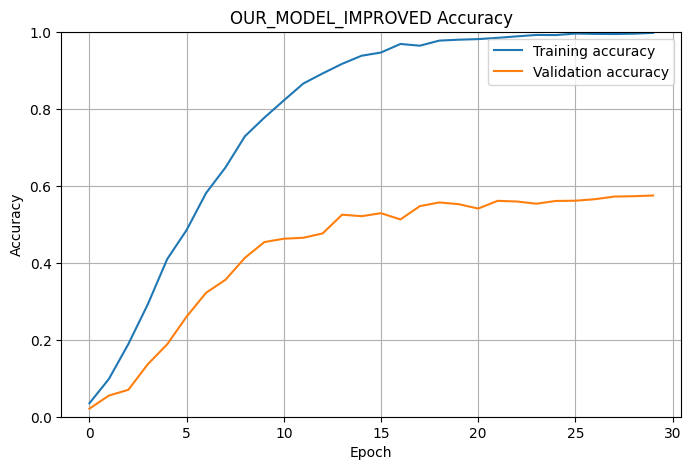

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

OUR_MODEL_IMPROVED: Test — loss: 1.8213, accuracy: 0.559


In [ ]:
create_model_and_train(use_residual=True,
                       use_batchnorm=True, use_label_smoothing=False,
                       experiment_name="OUR_MODEL_IMPROVED", num_epochs=30, data_loader=tr_no_augmentation)

## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `FGVCAircraft`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~70%.

## Proposed solution

We concatenate ResNet-18 with the same final classifier as before in part 1, which consists of:
1. Flatten layer;
2. Fully connected layer;
3. Batch Norm layer + ReLU;
4. Final fully connected layer, which outputs logits corresponding to the 100 aircraft models.

**Freezing VS Unfreezing the backbone model**: We saw in the lecture that *transfer learning* refers to importing a model with possibly frozen weights. On the other hand, in *fine-tuning* we do **not** freeze the weights, as it would mean in this case only using ResNet-18 generic knowledge. In contrast, we want to specialise the expressive power of ResNet to the aircraft domain, and we obtain that by allowing the weights to be trained on our particular aircraft dataset.

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

In [ ]:
# Utility function for instantiating our Resnet-18 with the same classifier and training recipe as our previsous model
def create_resnet_and_train(experiment_name, num_epochs, data_loader=tr):
  print(f"######### Training: {experiment_name} #########")
  device = "cuda" if torch.cuda.is_available() else "cpu"

  weights = ResNet18_Weights.DEFAULT
  resnet = resnet18(weights=weights)

  num_features = resnet.fc.in_features

  # add the same classifier as before with adapted input shape
  resnet.fc = nn.Sequential(
          nn.Flatten()
          ,nn.Linear(num_features, 512)
          ,nn.BatchNorm1d(512)
          ,nn.ReLU()
          ,nn.Linear(512, 100))
  opt = torch.optim.Adam(
      resnet.parameters(),
      lr=2e-4
  )

  loss_fn = nn.CrossEntropyLoss() # no label smoothing
  resnet = resnet.to(device)
  train_loss_per_epoch, train_acc_per_epoch, val_loss_per_epoch, val_acc_per_epoch = train_loop(resnet, opt, loss_fn, device, experiment_name=experiment_name, epochs=num_epochs, tr=data_loader)

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Loss")
  plt.plot(np.arange(num_epochs), np.array(train_loss_per_epoch), label="Training loss")
  plt.plot(np.arange(num_epochs), np.array(val_loss_per_epoch), label="Validation loss")
  plt.ylim(0, 10)
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Accuracy")
  plt.plot(np.arange(num_epochs), np.array(train_acc_per_epoch), label="Training accuracy")
  plt.plot(np.arange(num_epochs), np.array(val_acc_per_epoch), label="Validation accuracy")
  plt.ylim(0, 1)
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.grid(True)
  plt.show()

  resnet.eval()
  correct = total = 0
  test_loss = 0.0

  with torch.no_grad():
      for x, y in tqdm(test_loader, desc="Testing"):
          x, y = x.to(device), y.to(device)

          logits = resnet(x)
          loss = loss_fn(logits, y)

          test_loss += loss.item() * y.size(0)
          correct += (logits.argmax(1) == y).sum().item()
          total += y.size(0)

  test_loss /= total
  test_acc = correct / total

  print(f"{experiment_name}: Test — loss: {test_loss:.4f}, accuracy: {test_acc:.3f}")

######### Training: SAME_HYPERPARAMETERS #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

SAME_HYPERPARAMETERS:Validation — loss: 3.5628, accuracy: 0.195, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

SAME_HYPERPARAMETERS:Validation — loss: 2.8686, accuracy: 0.380, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

SAME_HYPERPARAMETERS:Validation — loss: 1.0314, accuracy: 0.720, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

SAME_HYPERPARAMETERS:Validation — loss: 1.0888, accuracy: 0.720, lr=2.00e-04


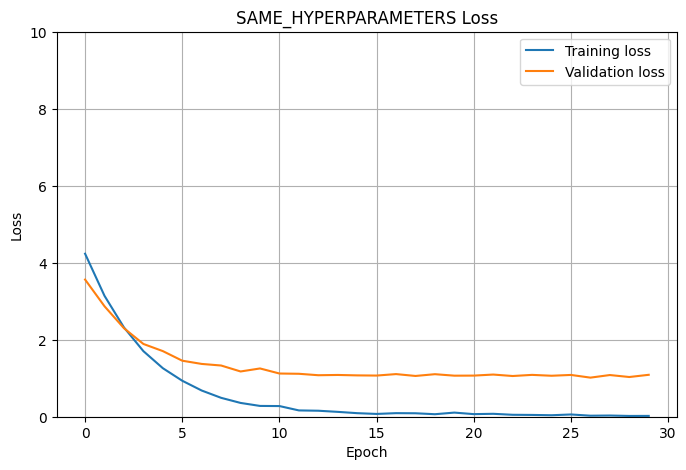

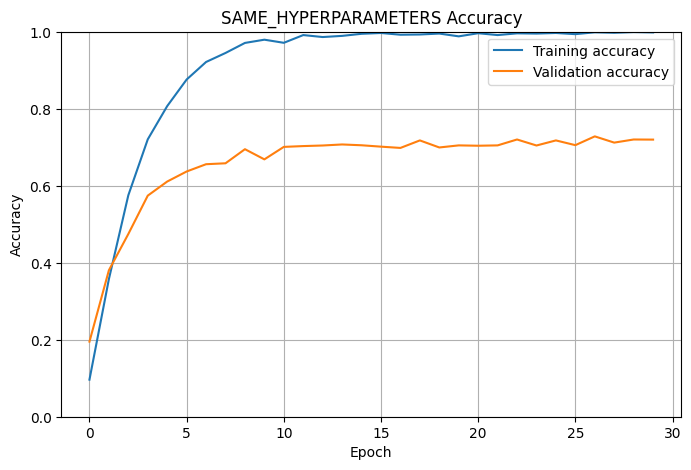

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

SAME_HYPERPARAMETERS: Test — loss: 1.1157, accuracy: 0.716


In [ ]:
create_resnet_and_train("SAME_HYPERPARAMETERS", num_epochs=30, data_loader=tr_no_augmentation)

Interestingly, keeping the same hyperparameters as in part 1, we already achieve more than 70% accuracy.

For 2B we will attempt to improve our result by tweaking the following aspects of the model:
- **Data augmentation**: As explained in the lecture, data augmentation exhibits similar benefits to having a larger dataset. Since ResNet-18 has more parameters than our previous model, we expect it to train better with this added regularization.
- **Modifying the final classifier**: We added an extra fully connected layer to the final classifier, as this could increase the expressiveness of the network.
- **Learning rates and epochs**: Since adding an extra FC layer led to mildly unstable results, we explored the effect of reducing the learning rate and train for longer, for stabilisation purposes.

For each experiment we are going to briefly outline the results. Finally, we will draw overall conclusions.

### **1st Experiment: Introducing data augmentation**:

We train the model introducing data augmentation. Surprisingly, we only got slightly better results, with accuracy peaking at 72% before starting to oscillate.

######### Training: RESNET_WITH_AUGMENTATION #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_AUGMENTATION:Validation — loss: 3.5293, accuracy: 0.200, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_AUGMENTATION:Validation — loss: 2.8388, accuracy: 0.410, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_AUGMENTATION:Validation — loss: 1.0815, accuracy: 0.707, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_AUGMENTATION:Validation — loss: 1.0802, accuracy: 0.714, lr=2.00e-04


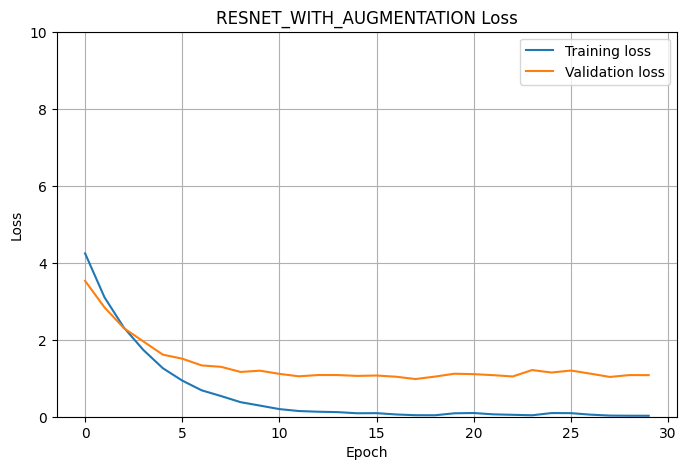

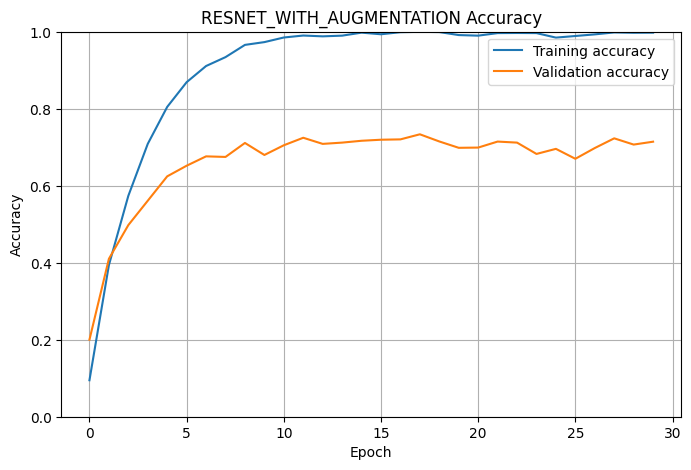

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_AUGMENTATION: Test — loss: 1.0477, accuracy: 0.727


In [ ]:
create_resnet_and_train("RESNET_WITH_AUGMENTATION", num_epochs=30, data_loader=tr)

## **2nd Experiment: Adding extra FC layer experiment with augmentation:**

One possible explaination for the underwelming improvement obtained with data augmentation, we tried to increase the model expressive power by adding to the final classifier an extra fully-connected layer. Interestingly, not only the performance did not improve, but the results showed mild unstability. We are going to try address that in the next experiment.

In [ ]:
# we modify the previous utility function for instantiating our Resnet-18, adding an additional fc-layer.
def create_resnet_and_train_extra_layer(experiment_name, num_epochs, data_loader=tr, learning_rate=2e-4):
  print(f"######### Training: {experiment_name} #########")
  device = "cuda" if torch.cuda.is_available() else "cpu"

  weights = ResNet18_Weights.DEFAULT
  resnet = resnet18(weights=weights)

  num_features = resnet.fc.in_features

  # add the same classifier as before with adapted input shape
  resnet.fc = nn.Sequential(
          nn.Flatten()
          ,nn.Linear(num_features, 512)
          ,nn.Linear(512, 512)
          ,nn.BatchNorm1d(512)
          ,nn.ReLU()
          ,nn.Linear(512, 100))
  opt = torch.optim.Adam(
      resnet.parameters(),
      lr=learning_rate
  )

  loss_fn = nn.CrossEntropyLoss() # no label smoothing
  resnet = resnet.to(device)
  train_loss_per_epoch, train_acc_per_epoch, val_loss_per_epoch, val_acc_per_epoch = train_loop(resnet, opt, loss_fn, device, experiment_name=experiment_name, epochs=num_epochs, tr=data_loader)

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Loss")
  plt.plot(np.arange(num_epochs), np.array(train_loss_per_epoch), label="Training loss")
  plt.plot(np.arange(num_epochs), np.array(val_loss_per_epoch), label="Validation loss")
  plt.ylim(0, 10)
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Accuracy")
  plt.plot(np.arange(num_epochs), np.array(train_acc_per_epoch), label="Training accuracy")
  plt.plot(np.arange(num_epochs), np.array(val_acc_per_epoch), label="Validation accuracy")
  plt.ylim(0, 1)
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.grid(True)
  plt.show()

  resnet.eval()
  correct = total = 0
  test_loss = 0.0

  with torch.no_grad():
      for x, y in tqdm(test_loader, desc="Testing"):
          x, y = x.to(device), y.to(device)

          logits = resnet(x)
          loss = loss_fn(logits, y)

          test_loss += loss.item() * y.size(0)
          correct += (logits.argmax(1) == y).sum().item()
          total += y.size(0)

  test_loss /= total
  test_acc = correct / total

  print(f"{experiment_name}: Test — loss: {test_loss:.4f}, accuracy: {test_acc:.3f}")

######### Training: RESNET_WITH_EXTRA_FC_layer #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 3.4880, accuracy: 0.213, lr=2.00e-04


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 2.7837, accuracy: 0.379, lr=2.00e-04


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 1.1431, accuracy: 0.695, lr=2.00e-04


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 1.1716, accuracy: 0.681, lr=2.00e-04


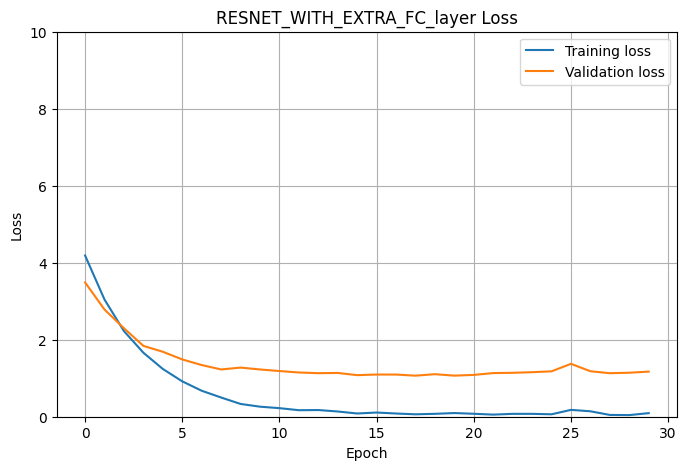

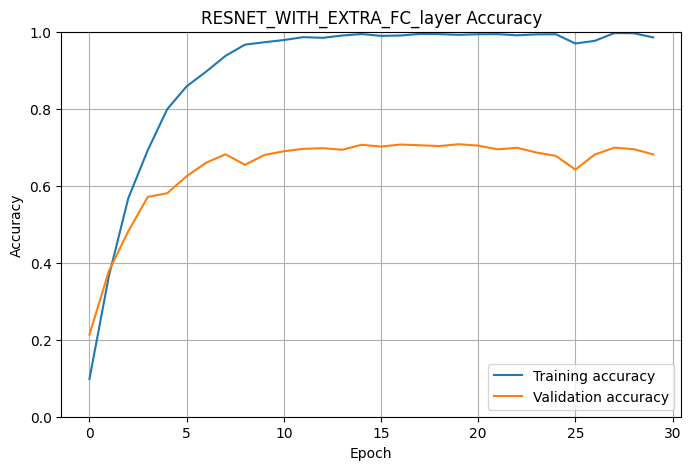

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer: Test — loss: 1.2076, accuracy: 0.685


In [ ]:
create_resnet_and_train_extra_layer("RESNET_WITH_EXTRA_FC_layer", num_epochs=30, data_loader=tr)

### **3rd Experiment: Extra FC-layer with augmentation *and* reduced learning rate:**

We addressed the partial instability of the scores in the previous experiment by reducing the learning rate. The model showed very stable but slowlier convergence, as expected. Since both the loss and the accuracy were monotonically decreasing and increasing, respectively, we decided in the last experiment to increase the number of epochs, to understand if that could be the bottleneck.

######### Training: RESNET_WITH_EXTRA_FC_layer #########


Epoch 1/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 4.5606, accuracy: 0.026, lr=2.00e-05


Epoch 2/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 4.4053, accuracy: 0.062, lr=2.00e-05


Epoch 3/30:   0%|          | 0/53 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 1.8014, accuracy: 0.637, lr=2.00e-05


Epoch 30/30:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer:Validation — loss: 1.7729, accuracy: 0.635, lr=2.00e-05


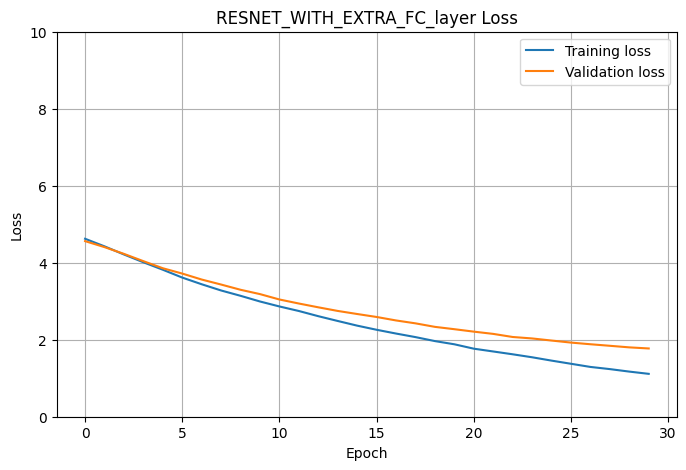

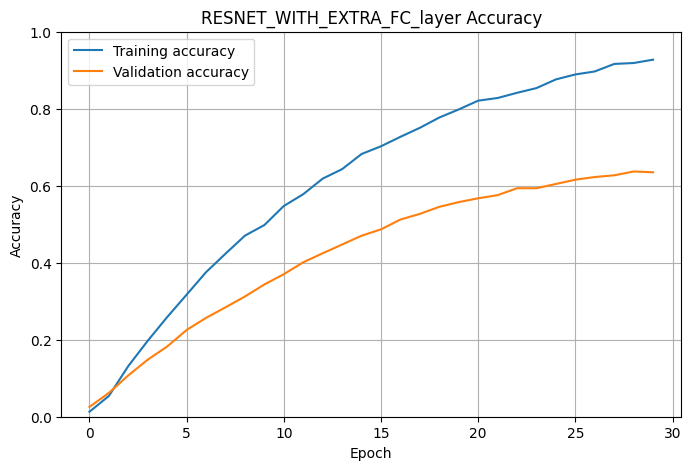

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

RESNET_WITH_EXTRA_FC_layer: Test — loss: 1.7795, accuracy: 0.639


In [ ]:
create_resnet_and_train_extra_layer("RESNET_WITH_EXTRA_FC_layer", num_epochs=30, data_loader=tr, learning_rate=2e-5)

### **4th Experiment: Longer training with small learning rate:**

We finally keep the small learning rate (2e-5) and train the model for 35 more epochs (hence 65 total). We do so by definig a custom function ```continue_training```. The model continues improving, untill reaching accuracy of around 70%, which is very similar to the accuracy we obtained with just 30 epochs, with no data augmentation (see 1st experiment). This seems to suggest that neither a lack of expressiveness of the final classifier, nor training time are an obstruction preventing the model to significantly improve.

In [ ]:
best_resnet_exp3 = resnet18()

num_features = best_resnet_exp3.fc.in_features

  # add the same classifier as before with adapted input shape
best_resnet_exp3.fc = nn.Sequential(
          nn.Flatten()
          ,nn.Linear(num_features, 512)
          ,nn.Linear(512, 512)
          ,nn.BatchNorm1d(512)
          ,nn.ReLU()
          ,nn.Linear(512, 100))

# Load the saved weights from Google Drive
model_path = "/content/drive/MyDrive/AssignmentsIPCV/assignment2/RESNET_WITH_EXTRA_FC_layer_aircraft_cnn_best.pth"
best_resnet_exp3.load_state_dict(torch.load(model_path))

<All keys matched successfully>

In [ ]:

def continue_training(experiment_name, num_epochs, model, data_loader=tr, learning_rate=2e-4):
  print(f"######### Training: {experiment_name} #########")
  device = "cuda" if torch.cuda.is_available() else "cpu"


  opt = torch.optim.Adam(
      model.parameters(),
      lr=learning_rate
  )

  loss_fn = nn.CrossEntropyLoss() # no label smoothing
  model = model.to(device)
  train_loss_per_epoch, train_acc_per_epoch, val_loss_per_epoch, val_acc_per_epoch = train_loop(model, opt, loss_fn, device, experiment_name=experiment_name, epochs=num_epochs, tr=data_loader)

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Loss")
  plt.plot(np.arange(num_epochs), np.array(train_loss_per_epoch), label="Training loss")
  plt.plot(np.arange(num_epochs), np.array(val_loss_per_epoch), label="Validation loss")
  plt.ylim(0, 10)
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.grid(True)
  plt.show()

  plt.figure(figsize=(8, 5))
  plt.title(f"{experiment_name} Accuracy")
  plt.plot(np.arange(num_epochs), np.array(train_acc_per_epoch), label="Training accuracy")
  plt.plot(np.arange(num_epochs), np.array(val_acc_per_epoch), label="Validation accuracy")
  plt.ylim(0, 1)
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.grid(True)
  plt.show()

  model.eval()
  correct = total = 0
  test_loss = 0.0

  with torch.no_grad():
      for x, y in tqdm(test_loader, desc="Testing"):
          x, y = x.to(device), y.to(device)

          logits = model(x)
          loss = loss_fn(logits, y)

          test_loss += loss.item() * y.size(0)
          correct += (logits.argmax(1) == y).sum().item()
          total += y.size(0)

  test_loss /= total
  test_acc = correct / total

  print(f"{experiment_name}: Test — loss: {test_loss:.4f}, accuracy: {test_acc:.3f}")

######### Training: More_training #########


Epoch 1/15:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.7218, accuracy: 0.644, lr=2.00e-05


Epoch 2/15:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.6758, accuracy: 0.647, lr=2.00e-05


Epoch 3/15:   0%|          | 0/53 [00:00<?, ?it/s]

... (21 outputs left out)

Epoch 14/15:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.3953, accuracy: 0.688, lr=2.00e-05


Epoch 15/15:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.3682, accuracy: 0.684, lr=2.00e-05


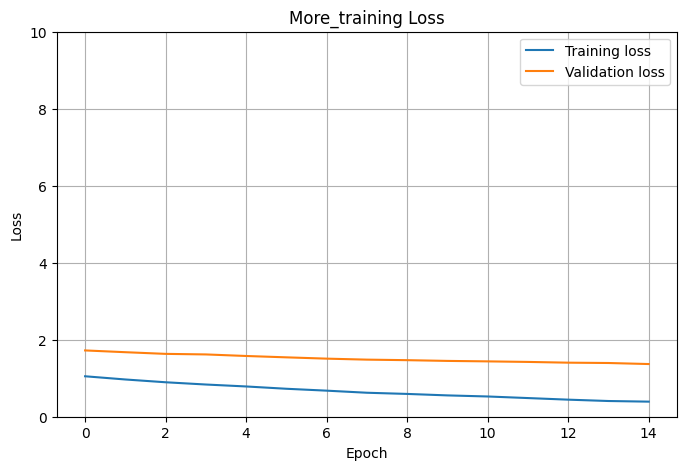

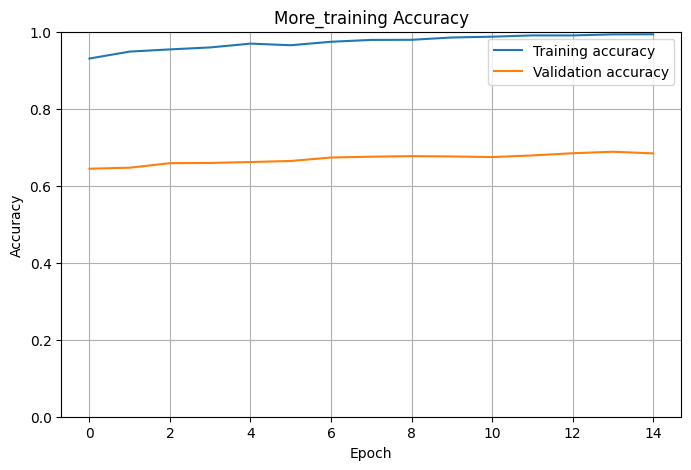

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

More_training: Test — loss: 1.3756, accuracy: 0.687


In [ ]:
continue_training("More_training", 15, best_resnet_exp3, data_loader=tr, learning_rate=2e-5)

######### Training: More_training #########


Epoch 1/20:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.3699, accuracy: 0.682, lr=2.00e-05


Epoch 2/20:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.3416, accuracy: 0.683, lr=2.00e-05


Epoch 3/20:   0%|          | 0/53 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19/20:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.1839, accuracy: 0.710, lr=2.00e-05


Epoch 20/20:   0%|          | 0/53 [00:00<?, ?it/s]

More_training:Validation — loss: 1.1808, accuracy: 0.706, lr=2.00e-05


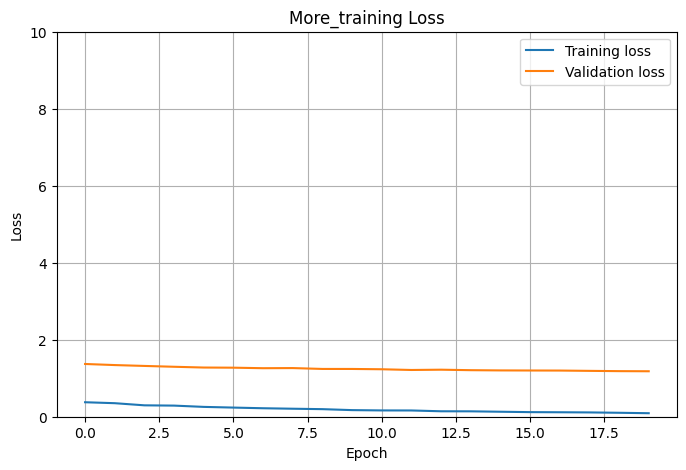

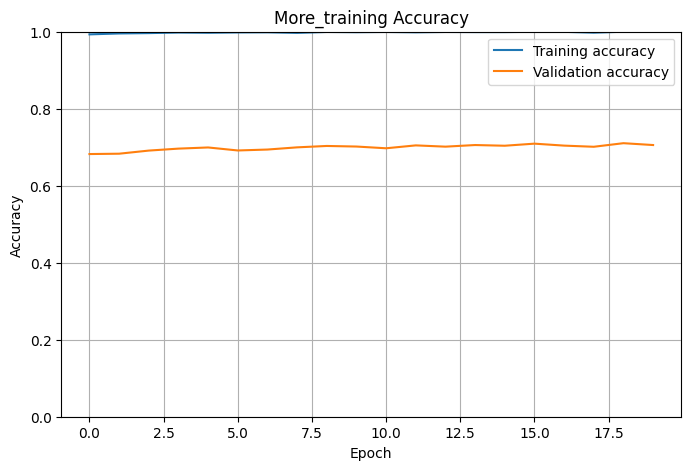

Testing:   0%|          | 0/53 [00:00<?, ?it/s]

More_training: Test — loss: 1.2068, accuracy: 0.701


In [ ]:
continue_training("More_training", 20, best_resnet_exp3, data_loader=tr, learning_rate=2e-5)

### Final Conclusions

Given the results obtained in our experiments, we can extract the following takeaways:

1. **Baseline Fine-Tuning Performance (2A):**
   - By using a pretrained ResNet-18 combined with our initial classifier and training recipe without data augmentation, we immediately surpassed the 70% threshold, reaching over **70% test accuracy** in 30 epochs. This highlights the effectiveness of using high-quality pre-trained weights from ImageNet through transfer learning.

2. **The Impact of Data Augmentation:**
   - Introducing data augmentation (Random Horizontal Flips, Rotations, and Color Jitter) only yielded a marginal improvement, with validation accuracy peaking around **72%**. This indicates that the pre-trained features were already highly representative, making further aggressive regularization less critical for this dataset. It could be interesting to try more diverse augmentation techniques and compare results.

3. **Classifier Complexity vs. Optimization Stability:**
   - Adding an extra fully connected layer to increase the expressive capacity of our network's head actually led to training instability and suboptimal performance when trained with the standard learning rate of `2e-4`.

4. **Optimization and Fine-Tuning with Low Learning Rates:**
   - To address this instability, reducing the learning rate to `2e-5` proved effective. This allowed for stable and monotonic convergence, though at a slower pace. Continuing this training for a total of 65 epochs allowed the model to steadily reach **70% validation accuracy**, which we had already achieved.

5. **Overall Takeaway:**
   - For fine-tuning ResNet-18 on the FGVC-Aircraft dataset, our simpler classifier head with the previous learning rate (2e-4) and no augmentation converges faster and performs comparably to a deeper classification head, which requires a much smaller learning rate and a significantly longer training schedule.



**Sources:** Lectures 4, 5, 6.